How RRT Finds a Path for a Robot Arm Through Clutter
====================================================

**Topic**: Path planning with Rapidly-exploring Random Trees (RRT) for a 2-DoF planar robot arm in a cluttered workspace

Version | Author | Remark
------------ | ------------- | -------------
0.1 | Course Add-on (based on Björn Hein & Gergely Sóti) | Interactive recreation of the *"How RRT finds a path for a robot arm through clutter"* animation

This notebook combines the concepts from **IP-2-0 (Work Space $\leftrightarrow$ Configuration Space)**, **IP-9-0 (RRT Basics)**, and **IP-10-0 (Planar Manipulator)**:

* **Top View (Work Space / Task Space)**: A 2-joint planar robot arm mounted on a pedestal must move from a **Start pose** (reaching left towards a conveyor belt) to a **Goal pose** (reaching right into a shelf) while avoiding multiple obstacles (cabinet, hanging sensor, crates, shelves).
* **Bottom View (Configuration Space / C-Space)**: Every pose of the arm corresponds to a single point $q = (j_1, j_2)$ given by the **Shoulder Angle ($j_1$)** and **Elbow Angle ($j_2$)**. Each obstacle in the workspace transforms into a colored collision region ($\mathcal{C}_{obs}$) of the same color in the configuration space.
* **RRT Exploration & Path Execution**: Because the planner does not know the C-space obstacles explicitly, it grows a tree from `START` by guessing random configurations (`SAMPLES`), testing extensions for collisions (red `X` and red ghost arm poses), and finally executing the discovered collision-free trajectory to `GOAL`.

**Dependencies**:
* `IPPlanarManipulator.py` (`PlanarRobot`), `IPEnvironmentKin.py` (`KinChainCollisionChecker`, `interpolate_line`), `IPRRT.py` (`RRTSimple`, `RRT`, `RRTEdges`), `IPVISRRTBasics.py` (`traceRRT`, `treeAtStep`)

In [1]:
import sys
sys.path.append(".")

import math
import random
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.animation
from matplotlib.colors import to_rgba
from matplotlib.patches import Rectangle, Patch
from matplotlib.lines import Line2D
from shapely.geometry import box, Polygon
from shapely import plotting
from IPython.display import HTML, display

from IPPlanarManipulator import PlanarRobot
from IPEnvironmentKin import KinChainCollisionChecker, interpolate_line
from IPRRT import RRTSimple, RRT, RRTEdges
import IPVISRRTBasics as visRRT

%matplotlib inline
matplotlib.rcParams["animation.embed_limit"] = 64

# 1. Setting up the 2-DoF Robot Arm and Cluttered Workspace

We use `PlanarRobot(n_joints=2)` from `IPPlanarManipulator.py` with two rotational joints ($j_1$: shoulder, $j_2$: elbow), each with link length $a = 1.5\text{ m}$ and capsule radius $r = 0.10\text{ m}$.

Around the robot base at $(0, 0)$, we place five distinct obstacles using **Shapely** polygons, matching the industrial scene:
1. **Conveyor** (dark gray, bottom-left)
2. **Cabinet** (taupe/gray, left of base)
3. **Hanging Sensor** (teal/blue-gray, top-center)
4. **Crates** (sand/tan, right of base)
5. **Shelves** (brown, far right)

In [2]:
# 2-DoF planar robot arm (two links of length 1.5 each)
robot = PlanarRobot(n_joints=2)
joint_limits = [[-math.pi, math.pi], [-math.pi, math.pi]]

# Cluttered workspace obstacles (Shapely geometries)
obstacles = {
    "Conveyor": (
        box(-2.95, -1.05, -1.35, -0.88)
        .union(box(-2.75, -1.50, -2.65, -1.05))
        .union(box(-1.60, -1.50, -1.50, -1.05))
    ),
    "Cabinet": box(-1.05, -1.50, -0.45, -0.10),
    "Hanging Sensor": box(0.85, 1.45, 1.25, 1.80).union(box(1.01, 1.80, 1.09, 2.95)),
    "Crates": box(0.45, -1.50, 1.35, -0.55),
    "Shelves": (
        box(1.75, 0.95, 3.00, 1.05)
        .union(box(1.75, 1.75, 3.00, 1.85))
        .union(box(1.75, -1.50, 1.85, -0.15))
        .union(box(1.75, -0.25, 3.00, -0.15))
    ),
}

# Distinct color palette matching the workspace objects and C-space regions
OBSTACLE_COLORS = {
    "Conveyor": "#4b534f",
    "Cabinet": "#9e988e",
    "Hanging Sensor": "#2d5a68",
    "Crates": "#c8a97e",
    "Shelves": "#a67c52",
}

# Kinematic chain collision checker (discretization step 0.06 rad, link capsule radius 0.10)
checker = KinChainCollisionChecker(
    robot, obstacles, limits=joint_limits, fk_resolution=0.06, link_radius=0.10
)

# Start configuration (reaching left towards the conveyor) & Goal configuration (reaching right into the shelf)
start_q = [2.35, 1.85]   # [j1 (Shoulder), j2 (Elbow)] in rad
goal_q  = [0.42, -0.42]  # [j1 (Shoulder), j2 (Elbow)] in rad

print("Start in collision?", checker.pointInCollision(start_q))
print("Goal in collision? ", checker.pointInCollision(goal_q))

Start in collision? False
Goal in collision?  False


# 2. Transforming Clutter into Configuration Space ($\mathcal{W} \rightarrow \mathcal{C}$)

As introduced in **IP-2-0**, a pose of the 2-DoF arm is a point $q = (j_1, j_2) \in [-\pi, \pi]^2$ in the 2D **Configuration Space (C-Space)**.
To visualize the C-space backdrop (labeled *"EVERY POSE OF THE ARM"*), we sample a grid over $[-\pi, \pi]^2$ and check which obstacle each configuration collides with.

> **Important**: Just like in the lecture, the RRT planner **does not know** these C-space obstacle shapes! The colored C-space map is only drawn for us as spectators so we can see how the RRT navigates through the narrow collision-free channel.

In [3]:
def sample_cspace_by_obstacle(robot, obstacles, limits, resolution=140, link_radius=0.10):
    """Sample the 2D C-space on a grid and record which obstacle (1..K) causes a collision."""
    per_obs_checkers = [
        KinChainCollisionChecker(robot, {name: obs}, limits=limits, link_radius=link_radius)
        for name, obs in obstacles.items()
    ]
    axes = [np.linspace(low, high, resolution) for low, high in limits]
    cspace = np.zeros((resolution, resolution), dtype=int)
    for i in range(resolution):
        for j in range(resolution):
            q = [axes[0][i], axes[1][j]]
            for k, chk in enumerate(per_obs_checkers, start=1):
                if chk.pointInCollision(q):
                    cspace[i, j] = k
                    break
    return axes, cspace

axes_cspace, cspace_grid = sample_cspace_by_obstacle(robot, obstacles, joint_limits, resolution=140)
free_pct = 100.0 * (1.0 - np.count_nonzero(cspace_grid) / cspace_grid.size)
print(f"Sampled {cspace_grid.size} poses: {np.count_nonzero(cspace_grid)} in collision, {free_pct:.1f}% collision-free.")

Sampled 19600 poses: 11687 in collision, 40.4% collision-free.


# 3. Visualization Helpers (Workspace & Configuration Space)

The helper functions below render the two stacked panels:
1. **`draw_arm_pose` / `draw_workspace_panel`**: Draws the robot pedestal, the colored factory obstacles, the translucent blue **Goal pose**, optional red colliding ghost poses (when an RRT branch hits an obstacle), and the active orange robot arm with a gripper.
2. **`draw_cspace_panel`**: Draws the C-space obstacle regions in matching colors, the growing RRT tree, random samples $q_{rand}$ (white circles with dashed lines), collisions (red `X`), and the final solution path.

In [4]:
def draw_arm_pose(ax, robot, q, color="#e67e30", alpha=1.0, lw=8.0,
                  draw_joints=True, draw_gripper=True, zorder=6):
    """Draw the 2-link robot arm with rotary joint markers and a parallel gripper at the end-effector."""
    robot.move(q)
    pts = np.array(robot.get_transforms(), dtype=float)
    ax.plot(pts[:, 0], pts[:, 1], color=color, alpha=alpha, linewidth=lw,
            solid_capstyle="round", zorder=zorder)
    if draw_joints:
        for p in pts[:-1]:
            ax.scatter([p[0]], [p[1]], s=lw * 11, color="#2b302c", edgecolor=color,
                       linewidth=2.0, alpha=alpha, zorder=zorder + 1)
    if draw_gripper:
        v = pts[2] - pts[1]
        v = v / (np.linalg.norm(v) + 1e-9)
        n = np.array([-v[1], v[0]])
        tip = pts[2]
        g1, g2 = tip + 0.14 * v + 0.09 * n, tip + 0.14 * v - 0.09 * n
        b1, b2 = tip + 0.09 * n, tip - 0.09 * n
        g_lw = max(2.0, lw * 0.35)
        ax.plot([b1[0], g1[0]], [b1[1], g1[1]], color="#4b534f", alpha=alpha, lw=g_lw, zorder=zorder + 1)
        ax.plot([b2[0], g2[0]], [b2[1], g2[1]], color="#4b534f", alpha=alpha, lw=g_lw, zorder=zorder + 1)
        ax.plot([b1[0], b2[0]], [b1[1], b2[1]], color="#4b534f", alpha=alpha, lw=g_lw, zorder=zorder + 1)


def draw_workspace_panel(ax, robot, obstacles, start_q, goal_q, current_q=None,
                         ghost_qs=None, colliding_segment=None, header_text=None):
    """Render the top panel: cluttered workspace + robot arm poses."""
    ax.set_xlim(-3.1, 3.1)
    ax.set_ylim(-1.5, 2.95)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_color("#6c7a72")
        spine.set_linewidth(3.0)

    # Robot base pedestal
    ax.add_patch(Rectangle((-0.22, -1.45), 0.44, 1.45, facecolor="#4b534f", edgecolor="none", zorder=2))
    ax.add_patch(Rectangle((-0.34, -1.50), 0.68, 0.10, facecolor="#363c39", edgecolor="none", zorder=2))
    ax.text(-0.78, -0.32, "Cabinet", fontsize=8, color="white", ha="center", zorder=4)
    ax.text(-2.15, -0.98, "Conveyor", fontsize=8, color="white", ha="center", va="center", zorder=4)
    ax.text(0.90, -1.05, "Crates", fontsize=8, color="#3a3022", ha="center", zorder=4)

    # Obstacles
    for name, geom in obstacles.items():
        c = OBSTACLE_COLORS[name]
        for g in getattr(geom, "geoms", [geom]):
            if isinstance(g, Polygon) and not g.is_empty:
                plotting.plot_polygon(g, ax=ax, add_points=False, facecolor=c, edgecolor=c, alpha=0.95, zorder=3)

    # Start & Goal ghost poses
    draw_arm_pose(ax, robot, start_q, color="#d0ceca", alpha=0.45, lw=6.5, draw_joints=False, draw_gripper=False, zorder=4)
    draw_arm_pose(ax, robot, goal_q, color="#a8c6e8", alpha=0.60, lw=7.0, draw_joints=True, draw_gripper=True, zorder=4)

    # Motion trail / ghost poses
    if ghost_qs:
        for i, gq in enumerate(ghost_qs):
            alpha_g = 0.14 + 0.24 * ((i + 1) / len(ghost_qs))
            draw_arm_pose(ax, robot, gq, color="#e67e30", alpha=alpha_g, lw=5.5,
                          draw_joints=False, draw_gripper=False, zorder=4)

    # Red ghost fan when an extension collides in workspace
    if colliding_segment is not None:
        q_from, q_to = np.array(colliding_segment[0]), np.array(colliding_segment[1])
        for t_fan in [0.35, 0.70, 1.0]:
            q_fan = (1.0 - t_fan) * q_from + t_fan * q_to
            draw_arm_pose(ax, robot, q_fan, color="#d9534f", alpha=0.25 + 0.18 * t_fan,
                          lw=6.5, draw_joints=False, draw_gripper=False, zorder=5)

    # Active orange robot arm
    draw_arm_pose(ax, robot, current_q if current_q is not None else start_q,
                  color="#e67e30", alpha=1.0, lw=8.5, zorder=7)

    if header_text:
        ax.set_title(header_text, fontsize=11.5, fontweight="bold", color="#222222", pad=10)


def draw_cspace_background(ax, axes, cspace, obstacles, start_q, goal_q):
    """Render the static C-space obstacle map and Start/Goal markers."""
    ax.set_xlim(-math.pi, math.pi)
    ax.set_ylim(-math.pi, math.pi)
    ax.set_facecolor("#f3f2ef")
    for k, name in enumerate(obstacles.keys(), start=1):
        mask = (cspace.T == k).astype(float)
        ax.contourf(axes[0], axes[1], mask, levels=[0.5, 1.5],
                    colors=[to_rgba(OBSTACLE_COLORS[name], 0.65)], zorder=2)

    # Start & Goal markers
    ax.scatter(*start_q, s=75, color="#e67e30", edgecolor="white", linewidth=1.5, zorder=9)
    ax.annotate("START", start_q, xytext=(-14, 9), textcoords="offset points",
                fontsize=9, fontweight="bold", color="#3a3a38", zorder=9)
    ax.scatter(*goal_q, s=95, facecolor="white", edgecolor="#2a6fdb", linewidth=2.2, zorder=9)
    ax.scatter(*goal_q, s=24, color="#2a6fdb", zorder=10)
    ax.annotate("GOAL", goal_q, xytext=(10, -4), textcoords="offset points",
                fontsize=9, fontweight="bold", color="#2a6fdb", zorder=9)

    ticks = [-math.pi, -math.pi / 2, 0, math.pi / 2, math.pi]
    labels = [r"$-\pi$", r"$-\frac{\pi}{2}$", "0", r"$\frac{\pi}{2}$", r"$\pi$"]
    ax.set_xticks(ticks)
    ax.set_xticklabels(labels, fontsize=9, color="#6c7a72")
    ax.set_yticks(ticks)
    ax.set_yticklabels(labels, fontsize=9, color="#6c7a72")
    ax.set_xlabel("SHOULDER ANGLE $j_1$ [rad]", fontsize=9, fontweight="bold", color="#6c7a72")
    ax.set_ylabel("ELBOW ANGLE $j_2$ [rad]", fontsize=9, fontweight="bold", color="#6c7a72")
    ax.set_title("EVERY POSE OF THE ARM (CONFIGURATION SPACE)", fontsize=10, fontweight="bold", color="#6c7a72", pad=8)

# 4. Recording the RRT Search Step-by-Step

We now run `traceRRT` from `IPVISRRTBasics.py` (which uses the same logic as `RRTEdges` / `RRT` in `IPRRT.py` while recording every random sample, extension, collision, and goal test).

RRT finished after 124 samples: 129 tree nodes, solution path has 35 waypoints.


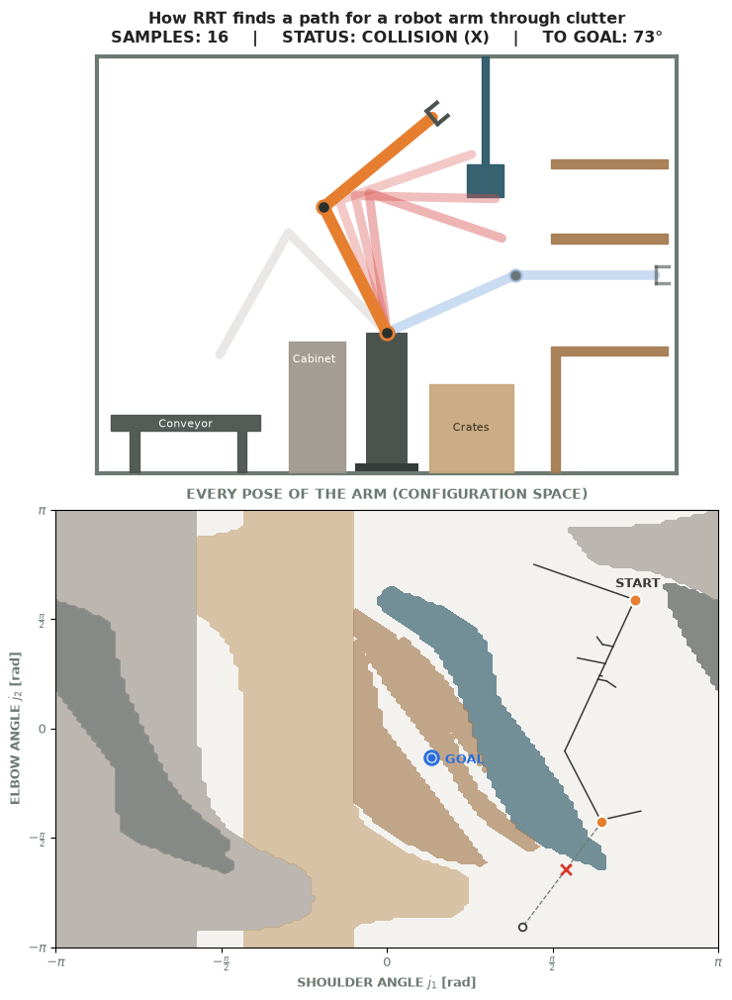

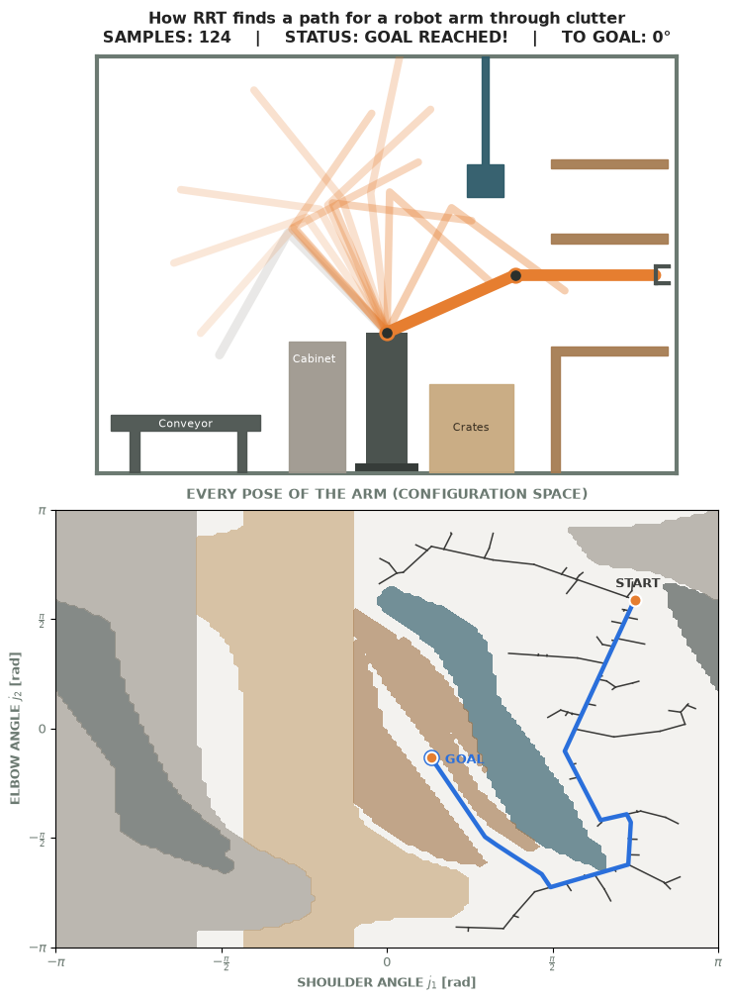

In [5]:
# Run RRT and record every step
tree, events, path = visRRT.traceRRT(
    checker, start_q, goal_q,
    numberOfGeneratedNodes=200,
    testGoalAfterNumberOfNodes=5,
    extendFraction=0.45,
    seed=42,
    nearestPoint=True
)

pos_all = nx.get_node_attributes(tree, "pos")
solution_waypoints = [pos_all[node] for node in path]
print(f"RRT finished after {len(events)} samples: {tree.number_of_nodes()} tree nodes, "
      f"solution path has {len(path)} waypoints.")


def plot_rrt_clutter_step(step, figsize=(7.5, 10.2)):
    """Plot the stacked Workspace + C-Space view at a specific RRT sample step."""
    step = max(0, min(step, len(events) - 1))
    tree_sub = visRRT.treeAtStep(start_q, events, step)
    ev = events[step]
    is_final = (step == len(events) - 1 and ev["type"] == "goalTest" and ev["result"] == "connected")

    if is_final:
        tree_sub.add_node("goal", pos=list(goal_q))
        tree_sub.add_edge(ev["near"], "goal")
        sol_nodes = nx.shortest_path(tree_sub, 0, "goal")
        curr_q = goal_q
        coll_seg = None
    elif ev["type"] == "extend":
        curr_q = ev["qNew"] if ev["result"] == "added" else ev["qNear"]
        coll_seg = (ev["qNear"], ev["qNew"]) if ev["result"] == "collision" else None
        sol_nodes = []
    else:
        curr_q = ev["qNear"]
        coll_seg = (ev["qNear"], goal_q) if ev["result"] == "collision" else None
        sol_nodes = []

    pos_dict = nx.get_node_attributes(tree_sub, "pos")
    min_dist_rad = min(math.dist(p, goal_q) for p in pos_dict.values())
    to_goal_deg = int(round(math.degrees(min_dist_rad)))
    status_str = "GOAL REACHED!" if is_final else ("COLLISION (X)" if coll_seg else "EXPLORING...")

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=figsize, gridspec_kw={"height_ratios": [1.0, 1.05]})

    ghosts = [pos_dict[n] for n in sol_nodes[1:-1:3]] if is_final else None
    header = (f"How RRT finds a path for a robot arm through clutter\n"
              f"SAMPLES: {step + 1}    |    STATUS: {status_str}    |    TO GOAL: {to_goal_deg}°")
    draw_workspace_panel(ax1, robot, obstacles, start_q, goal_q,
                         current_q=curr_q, ghost_qs=ghosts, colliding_segment=coll_seg, header_text=header)

    draw_cspace_background(ax2, axes_cspace, cspace_grid, obstacles, start_q, goal_q)
    for u, v in tree_sub.edges():
        p1, p2 = pos_dict[u], pos_dict[v]
        ax2.plot([p1[0], p2[0]], [p1[1], p2[1]], color="#3a3a38", linewidth=1.1, zorder=4)

    if not is_final:
        q_near = ev["qNear"]
        if ev["type"] == "extend":
            q_rand, q_new = ev["qRand"], ev["qNew"]
            ax2.scatter(*q_rand, s=30, facecolor="white", edgecolor="#3a3a38", linewidth=1.3, zorder=7)
            ax2.plot([q_near[0], q_rand[0]], [q_near[1], q_rand[1]], color="#6c7a72", linestyle="--", linewidth=0.9, zorder=5)
            if ev["result"] == "collision":
                ax2.scatter(*q_new, marker="x", s=60, color="#d93829", linewidths=2.0, zorder=8)
            else:
                ax2.plot([q_near[0], q_new[0]], [q_near[1], q_new[1]], color="#111111", linewidth=2.2, zorder=6)
        else:
            ax2.plot([q_near[0], goal_q[0]], [q_near[1], goal_q[1]], color="#d93829", linestyle="--", linewidth=1.1, zorder=5)
            mid = 0.5 * (np.array(q_near) + np.array(goal_q))
            ax2.scatter(*mid, marker="x", s=60, color="#d93829", linewidths=2.0, zorder=8)
    else:
        sol_pts = np.array([pos_dict[n] for n in sol_nodes])
        ax2.plot(sol_pts[:, 0], sol_pts[:, 1], color="#2a6fdb", linewidth=3.2, zorder=7)

    ax2.scatter(*curr_q, s=70, color="#e67e30", edgecolor="white", linewidth=1.5, zorder=10)
    fig.tight_layout()
    plt.show()

# Show a collision step (where the arm tests a pose hitting the hanging sensor) and the final connected path:
plot_rrt_clutter_step(15)
plot_rrt_clutter_step(len(events) - 1)

## Interactive Step-by-Step Explorer (`ipywidgets`)

Use the slider below to step through every single sample of the RRT search and watch how each sample in C-space corresponds to a physical arm pose in the workspace:

In [6]:
from ipywidgets import interact, IntSlider

interact(
    lambda step: plot_rrt_clutter_step(step, figsize=(7.0, 9.5)),
    step=IntSlider(min=0, max=len(events) - 1, step=1, value=15, description="RRT Step:")
);

interactive(children=(IntSlider(value=15, description='RRT Step:', max=123), Output()), _dom_classes=('widget-…

# 5. Full Animation: RRT Exploration + Smooth Path Execution

Just like in the Instagram video (and extending `animateSolution` from `IPEnvironmentKin.py`), the animation below has **two phases**:
1. **Phase 1 – RRT Exploration (`SLOW-MO` / `FAST`)**: The RRT tree grows in C-space, showing random samples (`o`), rejected colliding branches (red `x` and red ghost arm), and accepted branches.
2. **Phase 2 – Path Execution (`FOLLOW PATH`)**: Once `GOAL` is connected, the blue solution path is highlighted in C-space and the orange robot arm smoothly executes the collision-free trajectory from the conveyor belt through the overhead gap into the shelf.

In [7]:
def animate_rrt_through_clutter(robot, obstacles, axes, cspace, start_q, goal_q, events, solution_waypoints,
                                rrt_frame_stride=2, interp_step=0.08):
    """Create an HTML5 animation of (1) the RRT tree exploration and (2) the smooth robot trajectory execution."""
    # Build frames for Phase 1 (RRT exploration)
    explore_indices = list(range(0, len(events) - 1, rrt_frame_stride))
    if (len(events) - 1) not in explore_indices:
        explore_indices.append(len(events) - 1)

    # Build interpolated waypoints for Phase 2 (smooth execution along the solution path)
    smooth_path = [np.array(solution_waypoints[0], dtype=float)]
    for i in range(1, len(solution_waypoints)):
        seg = interpolate_line(solution_waypoints[i - 1], solution_waypoints[i], interp_step)
        smooth_path.extend(seg[1:])

    n_explore = len(explore_indices)
    n_execute = len(smooth_path)
    total_frames = n_explore + n_execute

    # Final tree and node positions for Phase 2
    final_tree = visRRT.treeAtStep(start_q, events, len(events) - 1)
    final_tree.add_node("goal", pos=list(goal_q))
    final_tree.add_edge(events[-1]["near"], "goal")
    final_pos = nx.get_node_attributes(final_tree, "pos")
    sol_pts = np.array(solution_waypoints, dtype=float)

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(7.2, 9.8), gridspec_kw={"height_ratios": [1.0, 1.05]})

    def update(frame_idx):
        ax1.cla()
        ax2.cla()

        if frame_idx < n_explore:
            # --- PHASE 1: RRT EXPLORATION ---
            step = explore_indices[frame_idx]
            tree_sub = visRRT.treeAtStep(start_q, events, step)
            ev = events[step]
            is_connected = (step == len(events) - 1 and ev["type"] == "goalTest" and ev["result"] == "connected")
            if is_connected:
                tree_sub.add_node("goal", pos=list(goal_q))
                tree_sub.add_edge(ev["near"], "goal")
                curr_q = goal_q
                coll_seg = None
            elif ev["type"] == "extend":
                curr_q = ev["qNew"] if ev["result"] == "added" else ev["qNear"]
                coll_seg = (ev["qNear"], ev["qNew"]) if ev["result"] == "collision" else None
            else:
                curr_q = ev["qNear"]
                coll_seg = (ev["qNear"], goal_q) if ev["result"] == "collision" else None

            pos_dict = nx.get_node_attributes(tree_sub, "pos")
            min_dist_rad = min(math.dist(p, goal_q) for p in pos_dict.values())
            to_goal_deg = int(round(math.degrees(min_dist_rad)))
            mode_str = "GOAL FOUND" if is_connected else ("SLOW-MO" if step < 25 else "EXPLORING")

            header = (f"How RRT finds a path for a robot arm through clutter\n"
                      f"SAMPLES: {step + 1}    |    PLAYBACK: {mode_str}    |    TO GOAL: {to_goal_deg}°")
            draw_workspace_panel(ax1, robot, obstacles, start_q, goal_q,
                                 current_q=curr_q, colliding_segment=coll_seg, header_text=header)

            draw_cspace_background(ax2, axes, cspace, obstacles, start_q, goal_q)
            for u, v in tree_sub.edges():
                p1, p2 = pos_dict[u], pos_dict[v]
                ax2.plot([p1[0], p2[0]], [p1[1], p2[1]], color="#3a3a38", linewidth=1.1, zorder=4)

            if not is_connected:
                q_near = ev["qNear"]
                if ev["type"] == "extend":
                    q_rand, q_new = ev["qRand"], ev["qNew"]
                    ax2.scatter(*q_rand, s=28, facecolor="white", edgecolor="#3a3a38", linewidth=1.3, zorder=7)
                    ax2.plot([q_near[0], q_rand[0]], [q_near[1], q_rand[1]], color="#6c7a72", linestyle="--", linewidth=0.9, zorder=5)
                    if ev["result"] == "collision":
                        ax2.scatter(*q_new, marker="x", s=55, color="#d93829", linewidths=2.0, zorder=8)
                    else:
                        ax2.plot([q_near[0], q_new[0]], [q_near[1], q_new[1]], color="#111111", linewidth=2.0, zorder=6)
            else:
                ax2.plot(sol_pts[:, 0], sol_pts[:, 1], color="#2a6fdb", linewidth=3.0, zorder=7)

            ax2.scatter(*curr_q, s=65, color="#e67e30", edgecolor="white", linewidth=1.5, zorder=10)

        else:
            # --- PHASE 2: SMOOTH PATH EXECUTION ---
            exec_idx = frame_idx - n_explore
            curr_q = smooth_path[exec_idx]
            rem_deg = int(round(math.degrees(math.dist(curr_q, goal_q))))
            trail = smooth_path[max(0, exec_idx - 12):exec_idx:3]

            header = (f"How RRT finds a path for a robot arm through clutter\n"
                      f"SAMPLES: {len(events)}    |    PLAYBACK: EXECUTE PATH    |    TO GOAL: {rem_deg}°")
            draw_workspace_panel(ax1, robot, obstacles, start_q, goal_q,
                                 current_q=curr_q, ghost_qs=trail, header_text=header)

            draw_cspace_background(ax2, axes, cspace, obstacles, start_q, goal_q)
            for u, v in final_tree.edges():
                p1, p2 = final_pos[u], final_pos[v]
                ax2.plot([p1[0], p2[0]], [p1[1], p2[1]], color="#b8b5b0", linewidth=0.9, zorder=3)

            ax2.plot(sol_pts[:, 0], sol_pts[:, 1], color="#2a6fdb", linewidth=3.2, zorder=6)
            ax2.scatter(*curr_q, s=90, color="#e67e30", edgecolor="white", linewidth=1.8, zorder=10)

        fig.tight_layout()

    ani = matplotlib.animation.FuncAnimation(fig, update, frames=total_frames, interval=90)
    html = HTML(ani.to_jshtml())
    plt.close(fig)
    display(html)

# Generate and display the interactive animation (takes ~15-20 seconds to render frames)
animate_rrt_through_clutter(
    robot, obstacles, axes_cspace, cspace_grid, start_q, goal_q,
    events, solution_waypoints, rrt_frame_stride=3, interp_step=0.09
)

# 6. Comparing the Course Planners (`RRTSimple`, `RRT`, `RRTEdges`) on This Scene

We can also run the three standard planner classes from `IPRRT.py` directly on our `checker` (`KinChainCollisionChecker`) and compare their trees and solution paths in C-space:

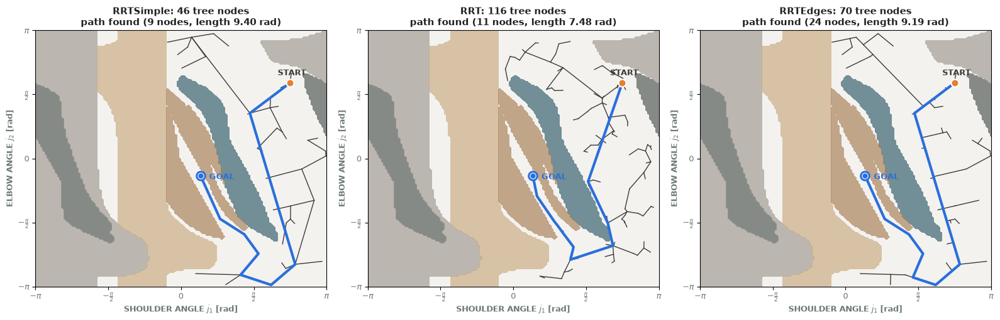

In [8]:
rrt_config = {
    "numberOfGeneratedNodes": 200,
    "testGoalAfterNumberOfNodes": 5
}

fig, axes_cmp = plt.subplots(1, 3, figsize=(16, 5.2))
for ax, PlannerClass in zip(axes_cmp, [RRTSimple, RRT, RRTEdges]):
    random.seed(42)
    np.random.seed(42)
    planner = PlannerClass(checker)
    sol = planner.planPath([start_q], [goal_q], rrt_config)

    draw_cspace_background(ax, axes_cspace, cspace_grid, obstacles, start_q, goal_q)
    pos_p = nx.get_node_attributes(planner.graph, "pos")
    for u, v in planner.graph.edges():
        ax.plot([pos_p[u][0], pos_p[v][0]], [pos_p[u][1], pos_p[v][1]], color="#3a3a38", linewidth=1.0, zorder=4)
    if sol:
        sol_xy = np.array([pos_p[n] for n in sol])
        ax.plot(sol_xy[:, 0], sol_xy[:, 1], color="#2a6fdb", linewidth=3.0, zorder=7)
        status = f"path found ({len(sol)} nodes, length {visRRT.pathLength(planner.graph, sol):.2f} rad)"
    else:
        status = "no path found"
    ax.set_title(f"{PlannerClass.__name__}: {planner.graph.number_of_nodes()} tree nodes\n{status}",
                 fontsize=10.5, fontweight="bold", color="#222222")

fig.tight_layout()
plt.show()